# 🐾 PawCare — Cat Detection & Breed Prediction

## Project Overview

This notebook is part of the **PawCare – Smart Pet Care & Safety Platform**.

It uses a two-stage deep learning pipeline:

### Stage 1 — Cat Detection
The first model determines whether the uploaded image contains a:

- Cat
- Non-Cat

### Stage 2 — Cat Breed Classification
If the image is detected as a cat, the second model predicts the cat breed from 11 supported breeds.

## Supported Cat Breeds

1. Abyssinian
2. Bengal
3. Bombay
4. British Shorthair
5. Egyptian Mau
6. Maine Coon
7. Persian
8. Ragdoll
9. Russian Blue
10. Siamese
11. Sphynx

## Models Used

- EfficientNetB0
- Transfer Learning
- TensorFlow / Keras
- Image size: 224 × 224

## Prediction Pipeline

**Image → Cat/Non-Cat Detector → Cat Breed Classifier → Top 3 Predictions**

In [1]:
# ==========================================
# CELL 2 - Import Libraries
# ==========================================

import os

# Reduce TensorFlow informational messages
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tkinter import Tk, filedialog
from tensorflow.keras.utils import load_img, img_to_array

print("======================================")
print("       PAWCARE AI PREDICTION")
print("======================================")
print()
print("TensorFlow version:", tf.__version__)
print("Python environment is ready!")

       PAWCARE AI PREDICTION

TensorFlow version: 2.21.0
Python environment is ready!


In [2]:
# ==========================================
# CELL 3 - Check Project Files
# ==========================================

PROJECT_DIR = Path.cwd()
MODELS_DIR = PROJECT_DIR / "models"

DETECTOR_MODEL_PATH = MODELS_DIR / "cat_detector.keras"
DETECTOR_CLASSES_PATH = MODELS_DIR / "cat_detector_class_names.json"

BREED_MODEL_PATH = MODELS_DIR / "cat_breed_classifier.keras"
BREED_CLASSES_PATH = MODELS_DIR / "class_names.json"


print("Project folder:")
print(PROJECT_DIR)

print("\nChecking model files...")
print("--------------------------------------")

files_to_check = [
    DETECTOR_MODEL_PATH,
    DETECTOR_CLASSES_PATH,
    BREED_MODEL_PATH,
    BREED_CLASSES_PATH
]

all_files_found = True

for file_path in files_to_check:

    if file_path.exists():
        print("✅", file_path.name)
    else:
        print("❌", file_path)
        all_files_found = False


if not all_files_found:
    raise FileNotFoundError(
        "\nSome required model files were not found. "
        "Make sure this notebook is inside the PawCare project folder."
    )

print("\n✅ All required model files are available.")

Project folder:
c:\Users\saisa\OneDrive\Documents\PawCare

Checking model files...
--------------------------------------
✅ cat_detector.keras
✅ cat_detector_class_names.json
✅ cat_breed_classifier.keras
✅ class_names.json

✅ All required model files are available.


In [3]:
# ==========================================
# CELL 4 - Load AI Models
# ==========================================

print("Loading Cat vs Non-Cat detector...")

detector_model = tf.keras.models.load_model(
    DETECTOR_MODEL_PATH
)

print("✅ Cat detector loaded successfully!")


print("\nLoading Cat Breed classifier...")

breed_model = tf.keras.models.load_model(
    BREED_MODEL_PATH
)

print("✅ Cat breed classifier loaded successfully!")


# Load class names
with open(DETECTOR_CLASSES_PATH, "r") as f:
    detector_classes = json.load(f)

with open(BREED_CLASSES_PATH, "r") as f:
    breed_classes = json.load(f)


print("\n======================================")
print("MODEL INFORMATION")
print("======================================")

print("\nDetector classes:")
print(detector_classes)

print("\nNumber of cat breeds:", len(breed_classes))

print("\nCat breeds:")
for number, breed in enumerate(breed_classes, start=1):
    print(f"{number}. {breed}")

print("\n✅ Both models are ready for prediction!")

Loading Cat vs Non-Cat detector...
✅ Cat detector loaded successfully!

Loading Cat Breed classifier...
✅ Cat breed classifier loaded successfully!

MODEL INFORMATION

Detector classes:
['cat', 'non_cat']

Number of cat breeds: 11

Cat breeds:
1. Abyssinian
2. Bengal
3. Bombay
4. British_Shorthair
5. Egyptian_Mau
6. Maine_Coon
7. Persian
8. Ragdoll
9. Russian_Blue
10. Siamese
11. Sphynx

✅ Both models are ready for prediction!


In [4]:
# ==========================================
# CELL 5 - Select Image
# ==========================================

print("Select an image for prediction.")

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

image_path = filedialog.askopenfilename(
    title="Select a Cat or Animal Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.webp"),
        ("JPG Files", "*.jpg *.jpeg"),
        ("PNG Files", "*.png"),
        ("WebP Files", "*.webp"),
        ("All Files", "*.*")
    ]
)

root.destroy()

if not image_path:

    print("\n❌ No image selected.")

else:

    image_path = Path(image_path)

    print("\n✅ Image selected:")
    print(image_path)

Select an image for prediction.

✅ Image selected:
C:\Users\saisa\Downloads\non_dog dataset\Persian\Persian_78.jpg


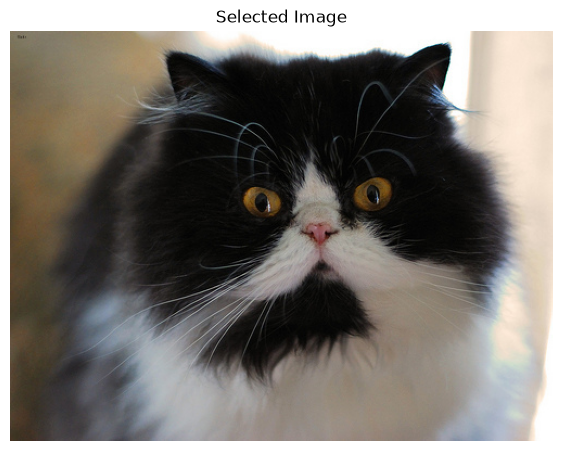

In [5]:
# ==========================================
# CELL 6 - Display Selected Image
# ==========================================

if not image_path:

    print("❌ No image selected.")

else:

    selected_image = load_img(image_path)

    plt.figure(figsize=(7, 7))
    plt.imshow(selected_image)
    plt.axis("off")
    plt.title("Selected Image")
    plt.show()

In [6]:
# ==========================================
# CELL 7 - Prepare Image
# ==========================================

IMG_SIZE = (224, 224)


def prepare_image(image_path):
    """
    Loads and prepares an image for EfficientNetB0.

    Image size:
        224 x 224

    Pixel values:
        Kept in the 0-255 range because
        EfficientNetB0 performs its own preprocessing.
    """

    image = load_img(
        image_path,
        target_size=IMG_SIZE
    )

    image_array = img_to_array(image)

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    return image_array


if image_path:

    prediction_image = prepare_image(image_path)

    print("✅ Image prepared successfully.")
    print("Image shape:", prediction_image.shape)

else:

    print("❌ Please select an image first.")

✅ Image prepared successfully.
Image shape: (1, 224, 224, 3)


In [7]:
# ==========================================
# CELL 8 - Stage 1: Cat Detection
# ==========================================

if not image_path:

    print("❌ No image selected.")

else:

    detector_prediction = detector_model.predict(
        prediction_image,
        verbose=0
    )[0]

    detector_index = np.argmax(
        detector_prediction
    )

    detector_label = detector_classes[
        detector_index
    ]

    detector_confidence = (
        detector_prediction[detector_index] * 100
    )


    print("======================================")
    print("       STAGE 1 - CAT DETECTION")
    print("======================================")

    print()
    print("Prediction :", detector_label)
    print(
        f"Confidence : {detector_confidence:.2f}%"
    )


    print("\nClass probabilities:")

    for index, class_name in enumerate(detector_classes):

        probability = detector_prediction[index] * 100

        print(
            f"{class_name:<10} : {probability:.2f}%"
        )

       STAGE 1 - CAT DETECTION

Prediction : cat
Confidence : 99.41%

Class probabilities:
cat        : 99.41%
non_cat    : 0.59%


In [8]:
# ==========================================
# CELL 9 - Stage 2: Cat Breed Classification
# ==========================================

if not image_path:

    print("❌ No image selected.")

elif detector_label == "non_cat":

    print("\n======================================")
    print("             RESULT")
    print("======================================")

    print("\n❌ This image is not detected as a cat.")
    print(
        f"Detector confidence: "
        f"{detector_confidence:.2f}%"
    )

    print(
        "\nThe cat breed classifier was not used."
    )


else:

    breed_prediction = breed_model.predict(
        prediction_image,
        verbose=0
    )[0]


    # Get top 3 predictions
    top_indices = np.argsort(
        breed_prediction
    )[::-1][:3]


    print("\n======================================")
    print("       STAGE 2 - CAT BREED")
    print("======================================")

    print("\nTop 3 predicted breeds:\n")


    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        breed_name = breed_classes[index]

        confidence = (
            breed_prediction[index] * 100
        )

        print(
            f"{rank}. "
            f"{breed_name:<20} "
            f"{confidence:.2f}%"
        )


    # Best prediction
    best_index = top_indices[0]

    best_breed = breed_classes[
        best_index
    ]

    best_confidence = (
        breed_prediction[best_index] * 100
    )


       STAGE 2 - CAT BREED

Top 3 predicted breeds:

1. Persian              91.27%
2. British_Shorthair    6.55%
3. Ragdoll              1.57%


In [9]:
# ==========================================
# CELL 10 - Final Result
# ==========================================

if not image_path:

    print("❌ No image selected.")

elif detector_label == "non_cat":

    print("\n")
    print("╔══════════════════════════════════════╗")
    print("║          PAWCARE AI RESULT           ║")
    print("╠══════════════════════════════════════╣")
    print("║                                      ║")
    print("║       ❌ NOT DETECTED AS CAT          ║")
    print("║                                      ║")
    print(
        f"║ Detector Confidence: "
        f"{detector_confidence:.2f}%       ║"
    )
    print("║                                      ║")
    print("╚══════════════════════════════════════╝")


else:

    print("\n")
    print("╔══════════════════════════════════════╗")
    print("║          PAWCARE AI RESULT           ║")
    print("╠══════════════════════════════════════╣")
    print("║                                      ║")
    print("║          🐱 CAT DETECTED              ║")
    print("║                                      ║")
    print(
        f"║ Breed: {best_breed:<25} ║"
    )
    print(
        f"║ Confidence: {best_confidence:.2f}%          ║"
    )
    print("║                                      ║")
    print("╚══════════════════════════════════════╝")


    print("\nTop 3 predictions:")

    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        breed_name = breed_classes[index]

        confidence = (
            breed_prediction[index] * 100
        )

        print(
            f"{rank}. "
            f"{breed_name} "
            f"({confidence:.2f}%)"
        )



╔══════════════════════════════════════╗
║          PAWCARE AI RESULT           ║
╠══════════════════════════════════════╣
║                                      ║
║          🐱 CAT DETECTED              ║
║                                      ║
║ Breed: Persian                   ║
║ Confidence: 91.27%          ║
║                                      ║
╚══════════════════════════════════════╝

Top 3 predictions:
1. Persian (91.27%)
2. British_Shorthair (6.55%)
3. Ragdoll (1.57%)


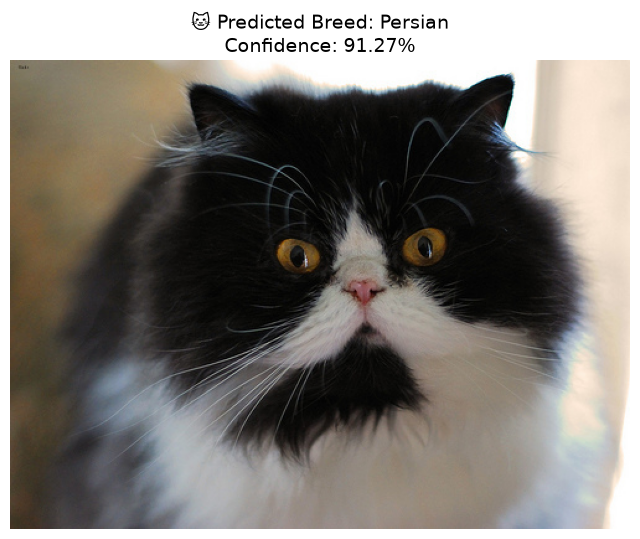

In [10]:
# ==========================================
# CELL 11 - Visual Result
# ==========================================

if not image_path:

    print("❌ No image selected.")

else:

    plt.figure(figsize=(8, 8))

    plt.imshow(
        load_img(image_path)
    )

    plt.axis("off")


    if detector_label == "non_cat":

        title = (
            "❌ NOT DETECTED AS CAT\n"
            f"Confidence: {detector_confidence:.2f}%"
        )

    else:

        title = (
            f"🐱 Predicted Breed: {best_breed}\n"
            f"Confidence: {best_confidence:.2f}%"
        )


    plt.title(
        title,
        fontsize=14
    )

    plt.show()

In [11]:
# ==========================================
# CELL 12 - Test Another Image
# ==========================================

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

new_image_path = filedialog.askopenfilename(
    title="Select Another Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.webp"),
        ("All Files", "*.*")
    ]
)

root.destroy()


if new_image_path:

    image_path = Path(new_image_path)

    print("✅ New image selected:")
    print(image_path)

else:

    print("❌ No new image selected.")

✅ New image selected:
C:\Users\saisa\OneDrive\Pictures\WhatsApp Image 2026-08-20 at 9.34.45 PM.jpeg


In [12]:
# ==========================================
# CELL 13 - ONE-CLICK PAWCARE PREDICTION
# ==========================================

def pawcare_predict():

    # -------------------------------
    # Select image
    # -------------------------------

    root = Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    selected_path = filedialog.askopenfilename(
        title="Select Image for PawCare Prediction",
        filetypes=[
            ("Image Files", "*.jpg *.jpeg *.png *.webp"),
            ("All Files", "*.*")
        ]
    )

    root.destroy()


    if not selected_path:

        print("❌ No image selected.")
        return


    selected_path = Path(selected_path)


    # -------------------------------
    # Display image
    # -------------------------------

    plt.figure(figsize=(6, 6))

    plt.imshow(
        load_img(selected_path)
    )

    plt.axis("off")
    plt.title("Selected Image")
    plt.show()


    # -------------------------------
    # Prepare image
    # -------------------------------

    image = prepare_image(
        selected_path
    )


    # -------------------------------
    # Stage 1
    # -------------------------------

    detector_prediction = (
        detector_model.predict(
            image,
            verbose=0
        )[0]
    )


    detector_index = np.argmax(
        detector_prediction
    )


    detector_label = detector_classes[
        detector_index
    ]


    detector_confidence = (
        detector_prediction[
            detector_index
        ] * 100
    )


    print("\n======================================")
    print("       PAWCARE AI PREDICTION")
    print("======================================")

    print("\nStage 1: Cat Detection")
    print(
        f"Result     : {detector_label}"
    )

    print(
        f"Confidence : "
        f"{detector_confidence:.2f}%"
    )


    # -------------------------------
    # Non-cat result
    # -------------------------------

    if detector_label == "non_cat":

        print("\n======================================")
        print("FINAL RESULT")
        print("======================================")

        print(
            "\n❌ This image is not detected as a cat."
        )

        print(
            "\nCat breed classification was skipped."
        )

        return


    # -------------------------------
    # Stage 2
    # -------------------------------

    breed_prediction = (
        breed_model.predict(
            image,
            verbose=0
        )[0]
    )


    top_indices = np.argsort(
        breed_prediction
    )[::-1][:3]


    best_index = top_indices[0]

    best_breed = breed_classes[
        best_index
    ]

    best_confidence = (
        breed_prediction[
            best_index
        ] * 100
    )


    # -------------------------------
    # Final result
    # -------------------------------

    print("\n======================================")
    print("FINAL RESULT")
    print("======================================")

    print(
        f"\n🐱 Predicted Breed: "
        f"{best_breed}"
    )

    print(
        f"📊 Confidence: "
        f"{best_confidence:.2f}%"
    )


    # -------------------------------
    # Top 3
    # -------------------------------

    print("\nTop 3 Predictions:")

    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        breed_name = breed_classes[
            index
        ]

        confidence = (
            breed_prediction[index] * 100
        )

        print(
            f"{rank}. "
            f"{breed_name:<20} "
            f"{confidence:.2f}%"
        )


    # -------------------------------
    # Visual final result
    # -------------------------------

    plt.figure(figsize=(7, 7))

    plt.imshow(
        load_img(selected_path)
    )

    plt.axis("off")

    plt.title(
        f"🐱 {best_breed}\n"
        f"Confidence: {best_confidence:.2f}%",
        fontsize=14
    )

    plt.show()

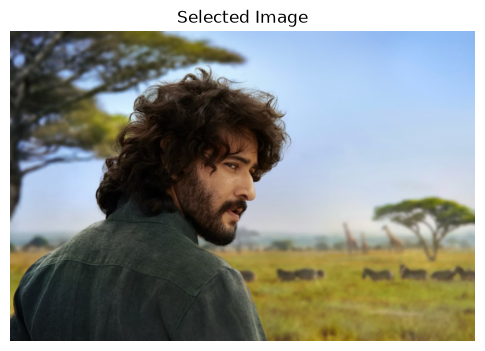


       PAWCARE AI PREDICTION

Stage 1: Cat Detection
Result     : non_cat
Confidence : 99.13%

FINAL RESULT

❌ This image is not detected as a cat.

Cat breed classification was skipped.


In [13]:
# ==========================================
# RUN PAWCARE
# ==========================================

pawcare_predict()

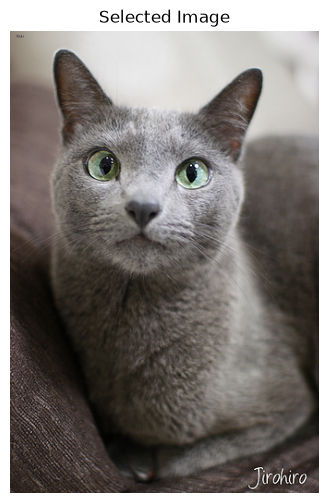


       PAWCARE AI PREDICTION

Stage 1: Cat Detection
Result     : cat
Confidence : 99.98%

FINAL RESULT

🐱 Predicted Breed: Russian_Blue
📊 Confidence: 90.39%

Top 3 Predictions:
1. Russian_Blue         90.39%
2. British_Shorthair    9.13%
3. Abyssinian           0.28%


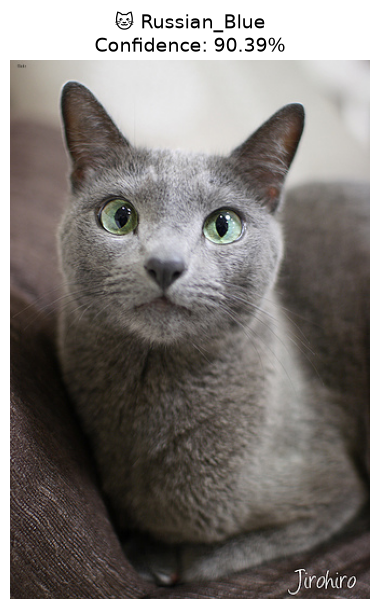

In [14]:
pawcare_predict()